In [1]:
import numpy as np
import scipy
import matplotlib.pyplot as plt
import seaborn as sns
import fastplotlib as fpl
from clustering.utils import generate_data, SpaceTimeSVD

To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Unable to find extension: VK_EXT_swapchain_colorspace


Available devices:
🯄 | AMD Radeon Graphics (RADV REMBRANDT) | IntegratedGPU | Vulkan | Mesa 22.3.6
✅ (default) | NVIDIA T1200 Laptop GPU | DiscreteGPU | Vulkan | 535.129.03
❗ | llvmpipe (LLVM 15.0.6, 256 bits) | CPU | Vulkan | Mesa 22.3.6 (LLVM 15.0.6)
❗ | AMD Radeon Graphics (rembrandt, LLVM 15.0.6, DRM 3.52, 6.4.0-0.deb12.2-amd64) | Unknown | OpenGL | 


In [2]:
%matplotlib inline

In [3]:
np.random.seed(0)

In [4]:
data, truth = generate_data(
    n_timepoints=1_000,
    n_components=3,
    noise=0,
    n_pixels=1,
    n_pixels_bg=0
)

In [5]:
data.shape

(3, 2000)

In [6]:
factor = 4

series = np.zeros((9 + 6, 2_000))

In [7]:
series[:3] = data[0]
series[3:6] = data[1]
series[6:9] = data[2]

series[9:12] = data[0] + data[1]
series[12:15] = data[1] + data[2]

In [8]:
series += np.vstack([np.random.normal(scale=10, size=2_000) for i in range(series.shape[0])])

In [9]:
series.shape

(15, 2000)

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterWgpuCanvas(css_height='500px', css_width='700px')
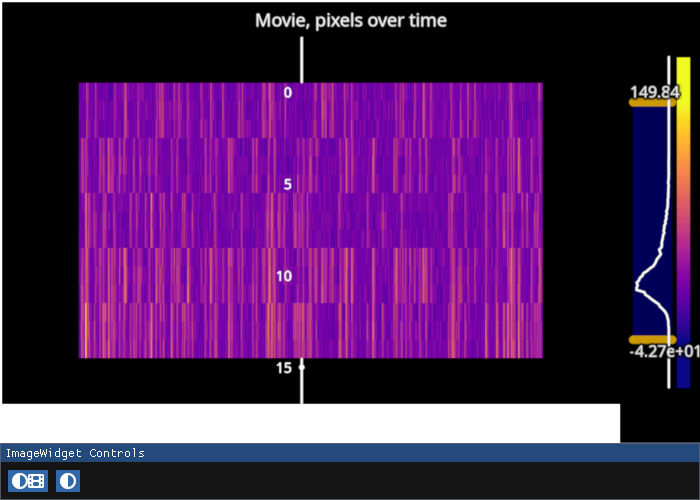

In [10]:
iw_series = fpl.ImageWidget(series, figure_kwargs={"size": (700, 500)})
iw_series.figure[0, 0].camera.maintain_aspect = False
iw_series.figure[0, 0].set_title("Movie, pixels over time")
iw_series.show()

In [11]:
iw_series.figure[0, 0].axes.y.ticks = {
    **{k: "1" for k in range(3)},
    **{k: "2" for k in range(3, 6)},
    **{k: "3" for k in range(6, 9)},
    **{k: "1 + 2" for k in range(9, 12)},
    **{k: "2 + 3" for k in range(12, 15)},
}

In [12]:
st_svd = SpaceTimeSVD(series, w=16)
st_svd.compute()

Computing F, P


100%|█████████████████████████████████████████████████████████████████████████████████████████| 15/15 [00:00<00:00, 8762.47it/s]


(15, 2000)
(120, 1984)


100%|█████████████████████████████████████████████████████████████████████████████████████████| 15/15 [00:00<00:00, 6929.68it/s]

computing H
Computing Hp
computimng svd of Hp


# $\mathbf{H = FP^T}$

# $\mathbf{H} \in \mathbb{R}^{pw \times pw}$

# Permute elements of H: $\mathbf{H} \rightarrow \mathbf{Hp} \in \mathbb{R}^{w^2 \times p^2}$

# SVD: $\mathbf{USV^T = Hp}$

# Reshape first right singular vector: $\mathbf{V^T} \rightarrow \mathbf{B} \in \mathbb{R}^{p \times p}$

RFBOutputContext()

JupyterWgpuCanvas()
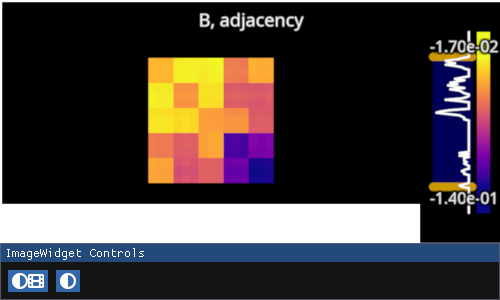

In [13]:
iw_adj = fpl.ImageWidget(st_svd.adjacency)
iw_adj.figure[0, 0].set_title("B, adjacency")
iw_adj.show()

In [18]:
np.linalg.norm((st_svd.adjacency - st_svd.adjacency.T), ord="fro") / np.linalg.norm(st_svd.adjacency, ord="fro")

np.float64(0.047248653619771784)

# $\mathbf{B} \approx \mathbf{B}^T$

# Force B to be symmetric $\mathbf{B'} = \frac{\mathbf{B + B^T}}{2}$

In [20]:
B = st_svd.adjacency
B = np.abs((B + B.T) / 2)

In [29]:
d = np.sum(B, axis=0)
d12 = np.diag(1 / np.sqrt(d))
a = d12 @ B @ d12
np.sum(a, axis=0)

array([0.77855687, 0.78012122, 0.78585755, 0.87416633, 0.85975446,
       0.86947565, 0.84027466, 0.82665337, 0.82628697, 1.16464629,
       1.16116218, 1.1686299 , 1.18869566, 1.1991283 , 1.1907827 ])

In [39]:
d = 1 / np.sum(B, axis=0)

In [44]:
a = np.diag(d) @ B

In [46]:
np.sum(a, axis=1)

array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])

<Axes: >

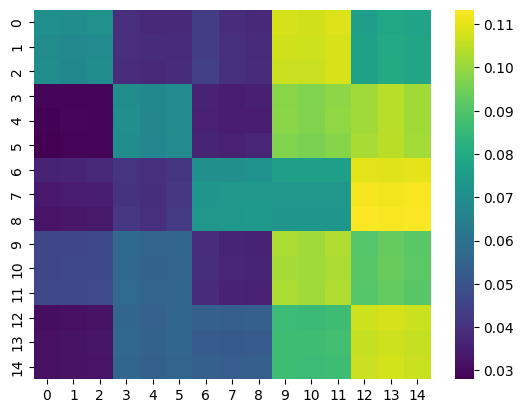

In [52]:
sns.heatmap(a, cmap="viridis")

<Axes: >

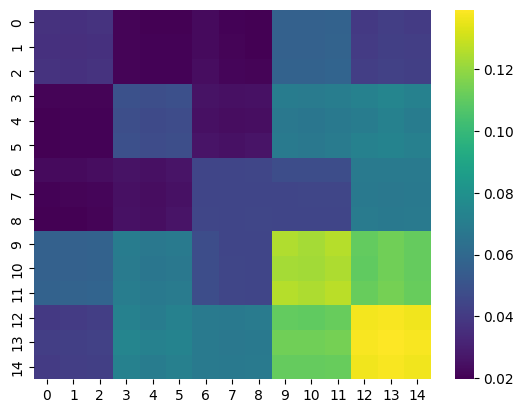

In [55]:
sns.heatmap(B, cmap="viridis")

<Axes: >

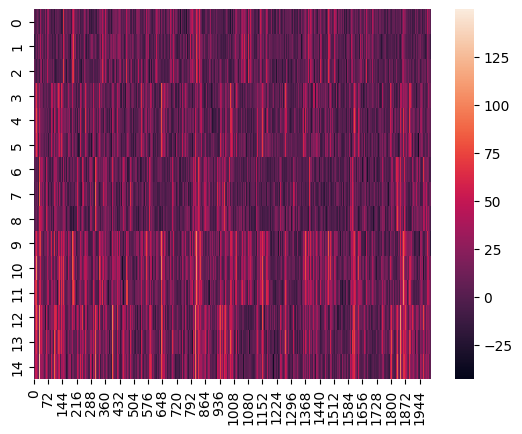

In [54]:
sns.heatmap(series)

In [56]:
import pygpcca as gp

In [57]:
gpcca = gp.GPCCA(a, z="LM", method="brandts")

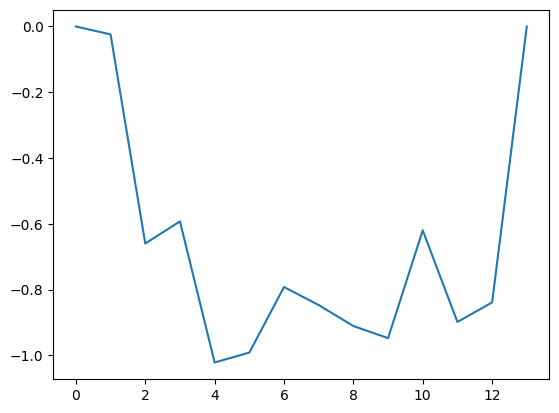

In [62]:
plt.plot(gpcca.minChi(2, 15))

In [63]:
gpcca.optimize({"m_min": 2, "m_max": 15})

/home/kushal/venvs/fpl/lib/python3.11/site-packages/pygpcca/_gpcca.py:1058: UserWarning: Clustering 15 data points into 15 clusters is always perfectly crisp. Thus m=15 won't be included in the search for the optimal cluster number.
  warnings.warn(


GPCCA[n=15, n_macrostates=3]

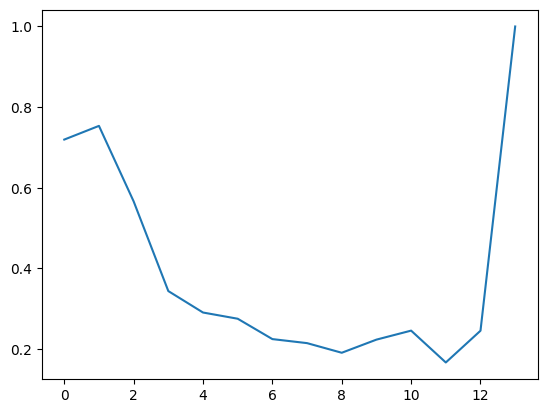

In [65]:
plt.plot(gpcca.crispness_values)

In [66]:
gpcca.top_eigenvalues

array([ 1.00000000e+00+0.j,  1.46506737e-01+0.j,  1.11626665e-01+0.j,
       -1.10977926e-03+0.j, -1.02749165e-03+0.j,  1.01331462e-03+0.j,
        9.62598120e-04+0.j, -7.74562972e-04+0.j,  6.15952432e-04+0.j,
       -4.45632788e-04+0.j,  4.03116565e-04+0.j, -2.89642993e-04+0.j,
        2.77382815e-04+0.j,  1.87161932e-04+0.j, -7.53571526e-05+0.j])

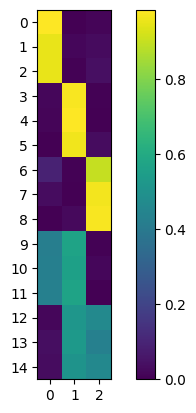

array([[9.85135984e-01, 9.95567211e-17, 1.48640162e-02],
       [9.51053524e-01, 1.82247086e-02, 3.07217677e-02],
       [9.53264624e-01, 4.64471377e-03, 4.20906623e-02],
       [1.68779021e-02, 9.76900281e-01, 6.22181720e-03],
       [1.53134123e-02, 9.82932671e-01, 1.75391632e-03],
       [2.38098981e-04, 9.65661730e-01, 3.41001707e-02],
       [9.50709494e-02, 6.22954782e-03, 8.98699503e-01],
       [3.30701409e-02, 1.93631096e-05, 9.66910496e-01],
       [8.93524452e-17, 2.39752681e-02, 9.76024732e-01],
       [4.22745563e-01, 5.72116995e-01, 5.13744190e-03],
       [4.23398609e-01, 5.60909391e-01, 1.56920004e-02],
       [4.27396233e-01, 5.72603767e-01, 0.00000000e+00],
       [1.88749483e-02, 5.15996447e-01, 4.65128605e-01],
       [3.67545045e-02, 5.32348955e-01, 4.30896540e-01],
       [3.31299506e-02, 5.07052510e-01, 4.59817539e-01]])

In [67]:
chi = gpcca.memberships
# plot chi:
fig, ax = plt.subplots()
c = ax.imshow(chi)
plt.xticks(np.arange(chi.shape[1]))
plt.yticks(np.arange(chi.shape[0]))
plt.ylim(-0.5, chi.shape[0]-0.5)
ax.set_ylim(ax.get_ylim()[::-1])
fig.colorbar(c)
plt.show()
# show chi matrix:
chi